# Schrödinger's box

An origami box printed on the inside with noise. Squeeze it flat one way and hold it up to a light, and two walls combine into a dead cat. Squeeze it the other way, and the other two walls show a live one. You can't squeeze both ways at once, so you never see the cat dead and alive together.

The model is the [hinged square box](https://origamiok.com/origami-hinged-square-box/): from a square of side `x`, the box side is `sqrt(2) / 6 * x`. The biggest square that fits on A4 is about 200 mm, so the box is about 47 mm wide. Its walls look about as tall as they are wide, but that still needs checking on a folded box.

The floor and lid aren't part of the overlay. Closing the lid leaves a gap as tall as the box, which breaks the illusion, so they can carry ordinary pictures (here, a flask of poison with a radiation symbol).

**The trick is visual cryptography** (Naor and Shamir, 1994). Light gets through a stack only where both layers are clear. So one wall can be random, and its opposite chosen to agree with it inside the picture and oppose it outside. Alone, a wall is the same random noise whatever the picture is.

The last section writes A4 sheets to print and test. They haven't been printed yet, so everything before that is a simulation. It needs only NumPy, Pillow and Matplotlib.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFilter, ImageFont

SHEET_MM = 200                 # the square you fold, the largest that fits on A4
BOX_MM = 2 ** 0.5 / 6 * SHEET_MM
PIXELS = 32                    # picture pixels up and across each wall
CELL_MM = BOX_MM / (2 * PIXELS)    # each picture pixel is 2 x 2 printed cells
SEED = 0
print(f"box side {BOX_MM:.2f} mm; {2 * PIXELS} x {2 * PIXELS} printed cells of {CELL_MM:.3f} mm")

box side 47.14 mm; 64 x 64 printed cells of 0.737 mm


## 1. The pictures

Each picture is drawn with smooth curves, then reduced to 32 × 32 black-and-white pixels. True means bright. At this size, details need to be about 2 pixels wide to survive, so the skeleton has a big skull, a thick curved spine and four ribs. The poses are compact to fill the square walls.

To use your own art, replace a drawing with `load_picture("my_cat.png")`: a bright subject on black, in a square image.

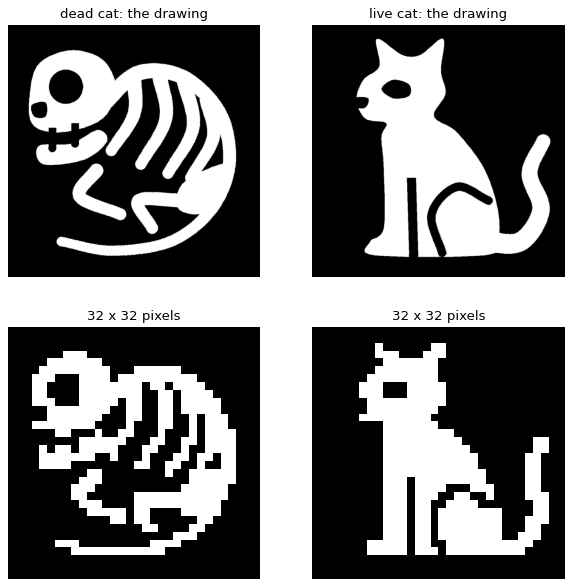

In [2]:
SS = 8                         # canvas pixels per drawing unit; pictures are drawn in 100 x 100 units

def spline(pts, closed=False, n=16):
    """Catmull-Rom through points."""
    P = np.asarray(pts, float)
    if closed: Q = np.vstack([P[-1], P, P[0], P[1]])
    else: Q = np.vstack([2*P[0]-P[1], P, 2*P[-1]-P[-2]])
    out = []
    for i in range(1, len(Q)-2):
        p0,p1,p2,p3 = Q[i-1],Q[i],Q[i+1],Q[i+2]
        for t in np.linspace(0,1,n,endpoint=False):
            out.append(.5*((2*p1)+(-p0+p2)*t+(2*p0-5*p1+4*p2-p3)*t*t+(-p0+3*p1-3*p2+p3)*t**3))
    if not closed: out.append(Q[-2])
    return np.array(out)

class Pen:
    def __init__(s, w=100, h=100):
        s.img = Image.new("L",(w*SS,h*SS),0); s.d = ImageDraw.Draw(s.img)
    def fill(s, pts, v=255, smooth=True):
        p = spline(pts,closed=True) if smooth else np.asarray(pts,float)
        s.d.polygon([tuple(q) for q in p*SS], fill=v)
    def stroke(s, pts, w0, w1=None, v=255, smooth=True):
        p = spline(pts) if smooth and len(pts)>2 else np.asarray(pts,float)
        w1 = w0 if w1 is None else w1
        ws = np.linspace(w0,w1,len(p))
        for a,b,w in zip(p[:-1],p[1:],ws):
            s.d.line([tuple(a*SS),tuple(b*SS)],fill=v,width=max(1,int(w*SS)))
            r=w*SS/2; s.d.ellipse([b[0]*SS-r,b[1]*SS-r,b[0]*SS+r,b[1]*SS+r],fill=v)
    def oval(s,cx,cy,rx,ry,v=255,angle=0):
        t=np.linspace(0,2*np.pi,48); c,si=np.cos(np.radians(angle)),np.sin(np.radians(angle))
        x,y=rx*np.cos(t),ry*np.sin(t)
        s.d.polygon([((cx+c*a-si*b)*SS,(cy+si*a+c*b)*SS) for a,b in zip(x,y)],fill=v)
    def array(s): return np.asarray(s.img,float)/255

def live_cat():
    """Sitting in profile, facing left, tail up. 100 x 100 units; about 3 units per pixel at 32."""
    p = Pen(100, 100)
    p.fill([(14, 28), (17, 19), (24, 13), (23, 1), (34, 8), (42, 8), (52, 1), (51, 15), (53, 25), (48, 35), (58, 42),
            (70, 58), (76, 76), (76, 90), (70, 96), (22, 96), (20, 90), (26, 84), (26, 58), (25, 44), (27, 38), (18, 36)])
    p.stroke([(70, 90), (86, 90), (95, 76), (90, 60), (96, 46)], 9, 6)   # tail
    p.fill([(25, 23), (30, 19), (37, 21), (37, 26), (30, 27)], v=0)       # eye
    p.fill([(13, 27), (19, 27), (18, 31), (14, 31)], v=0)                 # nose
    p.stroke([(38, 62), (39, 96)], 4, v=0)                                # gap between the front leg and body
    p.stroke([(52, 96), (47, 78), (58, 66), (72, 72)], 3.6, v=0)          # haunch
    return inset(p.array())

def dead_cat():
    """A skeleton curled on its side: big skull, thick ribs, curved spine."""
    p = Pen(100, 100)
    # Spine and tail, one long curve around the outside.
    p.stroke([(36, 30), (52, 16), (72, 18), (88, 34), (92, 56), (84, 76), (66, 90), (40, 94), (18, 90)], 7, 4)
    # Skull.
    p.fill([(4, 26), (8, 12), (22, 6), (36, 10), (42, 22), (38, 34), (28, 40), (14, 42), (5, 38)])
    p.oval(20, 22, 7.5, 7.5, 0)                                           # eye socket
    p.fill([(5, 30), (11, 29), (11, 35), (6, 35)], v=0)                   # nose
    p.fill([(8, 48), (22, 47), (34, 41), (38, 46), (28, 54), (10, 56)])   # jaw
    p.stroke([(14, 40), (14, 49)], 3.4, v=0)                              # gap in the teeth
    p.stroke([(24, 38), (24, 47)], 3.4, v=0)
    # Ribs, sweeping in from the spine.
    for root, mid, end in (((50, 18), (50, 34), (40, 50)), ((61, 16), (64, 36), (53, 56)),
                           ((72, 19), (76, 40), (65, 60)), ((82, 27), (85, 44), (75, 62))):
        p.stroke([root, mid, end], 6.4, 4.8)
    # Pelvis and a hind leg, folded in.
    p.fill([(92, 56), (84, 76), (70, 76), (72, 64)])
    p.stroke([(72, 72), (52, 72), (58, 84)], 6, 5)
    # Front leg, folded under the ribs.
    p.stroke([(34, 58), (26, 70), (44, 78)], 6, 5)
    return inset(p.array())

def inset(drawing, scale=0.9):
    """Shrink a drawing toward its center, so nothing touches the edge of the wall."""
    h, w = drawing.shape
    small = Image.fromarray((drawing * 255).astype(np.uint8)).resize((round(w * scale), round(h * scale)), Image.LANCZOS)
    out = Image.new("L", (w, h), 0)
    out.paste(small, ((w - small.width) // 2, (h - small.height) // 2))
    return np.asarray(out, float) / 255

def poison_flask():
    p=Pen(100,100)
    p.fill([(39,8),(61,8),(61,13),(58,13),(58,34),(86,82),(87,90),(82,94),(18,94),(13,90),(14,82),(42,34),(42,13),(39,13)],smooth=False)
    p.fill([(46,13),(54,13),(54,30),(46,30)],v=0,smooth=False)       # the neck's glass, dark
    c=np.array([50.,68.])
    for a in (-90,30,150):                                            # radiation symbol
        t=np.radians(np.linspace(a-30,a+30,24))
        arc=np.c_[np.cos(t),np.sin(t)]
        p.fill(np.vstack([c+8*arc,(c+21*arc)[::-1]]),v=0,smooth=False)
    p.oval(*c,5,5,0)
    for x,y,r in ((70,18,3),(78,8,4.5),(28,20,3.5),(22,8,2.5)):      # bubbles
        p.oval(x,y,r,r)
    return p.array()

def to_pixels(drawing, width=PIXELS, threshold=0.5):
    height = drawing.shape[0] * width // drawing.shape[1]
    img = Image.fromarray((np.clip(drawing, 0, 1) * 255).astype(np.uint8)).resize((width, height), Image.BOX)
    return np.asarray(img, float) / 255 > threshold

def load_picture(path, invert=False):
    drawing = np.asarray(Image.open(path).convert("L"), float) / 255
    return 1 - drawing if invert else drawing

drawings = {"dead cat": dead_cat(), "live cat": live_cat()}
pictures = {name: to_pixels(d) for name, d in drawings.items()}

fig, axes = plt.subplots(2, 2, figsize=(9, 9))
for col, (name, d) in zip(axes.T, drawings.items()):
    col[0].imshow(d, cmap="gray"); col[0].set_title(name + ": the drawing")
    col[1].imshow(pictures[name], cmap="gray", interpolation="nearest"); col[1].set_title(f"{PIXELS} x {PIXELS} pixels")
for ax in axes.ravel():
    ax.axis("off")
plt.show()

## 2. The noise

Each picture pixel becomes a block of 2 × 2 printed cells, two clear and two black, in one of 6 arrangements chosen at random.

- **Wall A** gets a random arrangement.
- **Wall B** gets the same arrangement where the picture is bright, and the opposite one where it's dark.

Stacked, a bright pixel stays half clear, and a dark pixel goes fully black, so the picture glows on black.

In [3]:
ARRANGEMENTS = np.array([[[1, 1], [0, 0]], [[0, 0], [1, 1]], [[1, 0], [1, 0]],
                         [[0, 1], [0, 1]], [[1, 0], [0, 1]], [[0, 1], [1, 0]]], bool)

def make_faces(picture, rng):
    """Two walls for a picture, in stacked coordinates. True = clear."""
    h, w = picture.shape
    a = ARRANGEMENTS[rng.integers(0, 6, (h, w))]
    b = np.where(picture[..., None, None], a, ~a)
    flat = lambda x: x.transpose(0, 2, 1, 3).reshape(2 * h, 2 * w)
    return flat(a), flat(b)

rng = np.random.default_rng(SEED)
faces = {name: make_faces(pic, rng) for name, pic in pictures.items()}

## 3. The two illusions

Each row shows the two walls alone, the stack, and the stack softened a little, roughly as it would look from arm's length.

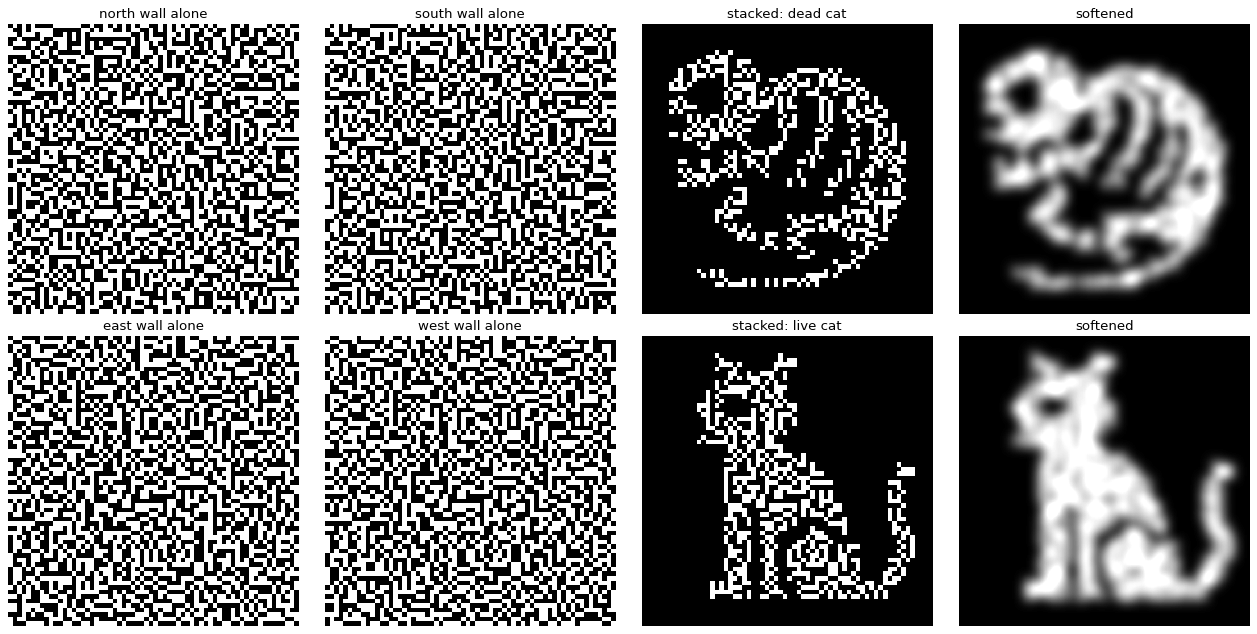

In [4]:
def soften(stack, sigma=1.3):
    img = Image.fromarray((stack * 255).astype(np.uint8)).resize((stack.shape[1] * 8, stack.shape[0] * 8), Image.NEAREST)
    return np.asarray(img.filter(ImageFilter.GaussianBlur(sigma * 8)), float) / 255 * 2     # half clear shows as white

labels = {"dead cat": ("north wall", "south wall"), "live cat": ("east wall", "west wall")}
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for row, (name, (a, b)) in zip(axes, faces.items()):
    first, second = labels[name]
    for ax, image, title in ((row[0], a, first + " alone"), (row[1], b, second + " alone"),
                             (row[2], a & b, f"stacked: {name}"), (row[3], soften(a & b), "softened")):
        ax.imshow(np.clip(image, 0, 1), cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        ax.set_title(title)
        ax.axis("off")
fig.tight_layout()
plt.show()

### Do the walls give anything away?

A wall alone should look the same whatever the picture is, and walls from different pairs should show nothing together. This compares the share of clear cells inside and outside each picture, and the same for a mismatched pair.

In [5]:
for name, (a, b) in faces.items():
    inside = np.repeat(np.repeat(pictures[name], 2, 0), 2, 1)
    stack = a & b
    print(name)
    print(f"  wall A: clear {a[inside].mean():.1%} inside, {a[~inside].mean():.1%} outside")
    print(f"  wall B: clear {b[inside].mean():.1%} inside, {b[~inside].mean():.1%} outside")
    print(f"  stacked: clear {stack[inside].mean():.1%} where bright, {stack[~inside].mean():.1%} where dark")

mixed = faces["dead cat"][0] & faces["live cat"][1]
inside = np.repeat(np.repeat(pictures["dead cat"], 2, 0), 2, 1)
print(f"\nmismatched pair (north + west): clear {mixed[inside].mean():.1%} inside the dead cat, "
      f"{mixed[~inside].mean():.1%} outside, so no picture shows")

dead cat
  wall A: clear 50.0% inside, 50.0% outside
  wall B: clear 50.0% inside, 50.0% outside
  stacked: clear 50.0% where bright, 0.0% where dark
live cat
  wall A: clear 50.0% inside, 50.0% outside
  wall B: clear 50.0% inside, 50.0% outside
  stacked: clear 50.0% where bright, 0.0% where dark

mismatched pair (north + west): clear 26.4% inside the dead cat, 25.9% outside, so no picture shows


## 4. How much misalignment can it take?

When the walls slip by a fraction `f` of a cell in one direction, only `1 - f` of each cell still sits on its partner. The rest sits on a neighbor, which actively hurts: each block has exactly two clear cells, so neighbors tend to be opposite. On average that gives a contrast of `1 - 7f/6`. A slip in both directions roughly multiplies the two.

slip in cells    in mm   one direction: measured  1 - 7f/6   both directions: measured
   0.00         0.00                    100%     100%                      100%
   0.25         0.18                     70%      71%                       50%
   0.50         0.37                     41%      42%                       15%
   0.75         0.55                     11%      12%                       -5%
   1.00         0.74                    -18%     -17%                      -10%


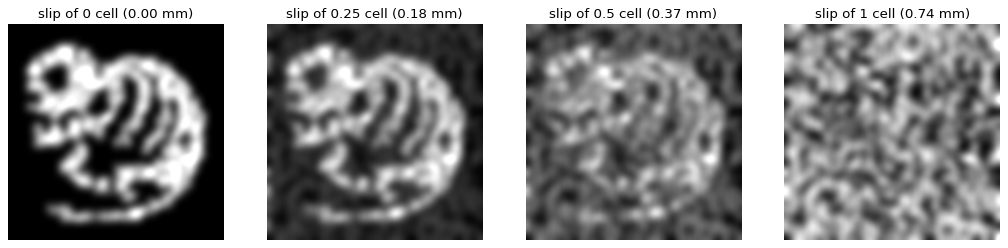

In [6]:
def shifted_stack(a, b, dx, dy, scale=8):
    up = lambda x: np.repeat(np.repeat(x, scale, 0), scale, 1)
    return up(a) & np.roll(np.roll(up(b), round(dx * scale), 1), round(dy * scale), 0), scale

def contrast(picture, a, b, dx, dy):
    stack, scale = shifted_stack(a, b, dx, dy)
    inside = np.repeat(np.repeat(picture, 2 * scale, 0), 2 * scale, 1)
    return stack[inside].mean() - stack[~inside].mean()

pic = pictures["live cat"]
a, b = faces["live cat"]
base = contrast(pic, a, b, 0, 0)
print("slip in cells    in mm   one direction: measured  1 - 7f/6   both directions: measured")
for f in (0, 0.25, 0.5, 0.75, 1):
    print(f"   {f:4.2f}       {f * CELL_MM:6.2f}                  {contrast(pic, a, b, f, 0) / base:6.0%}   {1 - 7 * f / 6:6.0%}"
          f"                    {contrast(pic, a, b, f, f) / base:6.0%}")

slips = (0, 0.25, 0.5, 1)
a, b = faces["dead cat"]
fig, axes = plt.subplots(1, len(slips), figsize=(16, 4.2))
for ax, f in zip(axes, slips):
    stack, _ = shifted_stack(a, b, f, 0)
    img = Image.fromarray((stack * 255).astype(np.uint8)).filter(ImageFilter.GaussianBlur(10))
    ax.imshow(np.clip(np.asarray(img, float) / 255 * 2, 0, 1), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"slip of {f:g} cell ({f * CELL_MM:.2f} mm)")
    ax.axis("off")
plt.show()

## 5. Sheets to print

Two A4 sheets, **A** and **B**. Each has both cats at three cell sizes, from forgiving to the real box:

| Cell size | Picture size | What it tests |
|---|---|---|
| 1.4 mm | 90 mm | Does the effect work at all with your paper and ink? |
| 1.0 mm | 64 mm | A middle step |
| 0.74 mm | 47 mm | The real box size |

**To test:**

1. Print both at **100%, not "fit to page"**, at your printer's highest quality, and check the 100 mm bar on each. Both must come from the same printer with the same settings.
2. Lay A on B with both **printed sides up**, and don't flip either one. Hold them against a window or bright lamp.
3. Line up the crosses at the corners of one picture. Each picture has its own crosses, in case the sheets don't line up perfectly across the whole page.

It also writes `prints/faces/`, the four walls and the floor at actual size, to place on your folded sheet. In those wall files, south and west are mirrored, because squeezed walls press their printed sides together. Then the picture reads correctly looking through the south or west wall with the light behind. The test sheets aren't mirrored, because both are printed side up.

saved faces test_sheet_A.pdf test_sheet_B.pdf and 5 files in faces/


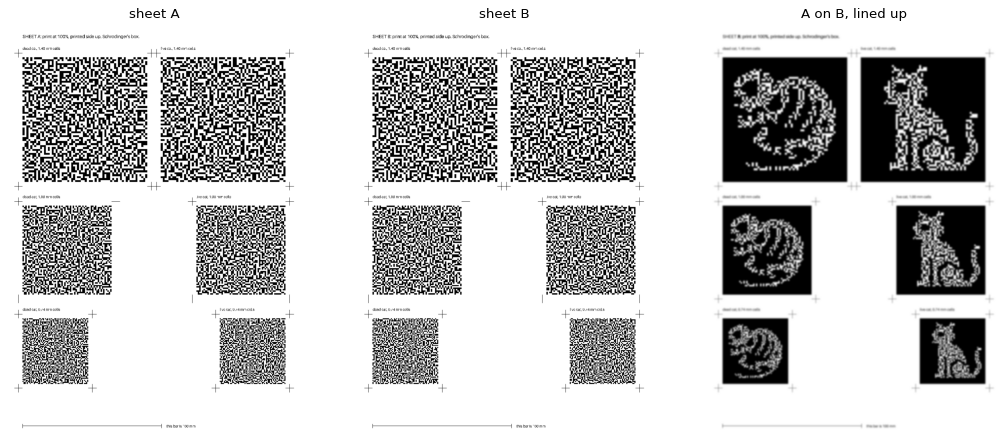

In [7]:
DPI = 600
OUT = "prints"
SIZES = (1.4, 1.0, CELL_MM)    # cell sizes in mm, largest first

def px(mm):
    return round(mm / 25.4 * DPI)

def render(cells, cell_mm):
    """Cells drawn at print resolution. Each boundary is rounded to the nearest printer dot."""
    n = round(cells.shape[0] * cell_mm / 25.4 * DPI), round(cells.shape[1] * cell_mm / 25.4 * DPI)
    rows = np.minimum(((np.arange(n[0]) + 0.5) * cells.shape[0] / n[0]).astype(int), cells.shape[0] - 1)
    cols = np.minimum(((np.arange(n[1]) + 0.5) * cells.shape[1] / n[1]).astype(int), cells.shape[1] - 1)
    return cells[np.ix_(rows, cols)]

def cross(draw, x, y):
    arm, width = px(3), max(1, px(0.15))
    draw.line([x - arm, y, x + arm, y], fill=0, width=width)
    draw.line([x, y - arm, x, y + arm], fill=0, width=width)

def font(mm):
    try:
        return ImageFont.load_default(size=px(mm))
    except TypeError:          # Pillow before 10.1
        return None

def make_sheet(which):
    """One A4 test sheet, as a 1-bit image: white is clear paper, black is ink."""
    W, H = px(210), px(297)
    page = Image.new("1", (W, H), 1)
    draw = ImageDraw.Draw(page)
    draw.text((px(10.5), px(7)), f"SHEET {which}: print at 100%, printed side up. Schrodinger's box.", fill=0, font=font(3.2))
    y = px(16)
    for cell_mm in SIZES:
        x = px(10.5)
        for name in ("dead cat", "live cat"):
            cells = faces[name]["AB".index(which)]
            art = render(cells, cell_mm)
            draw.text((x, y), f"{name}, {cell_mm:.2f} mm cells", fill=0, font=font(2.6))
            top = y + px(8)
            page.paste(Image.fromarray(art), (x, top))
            h, w = art.shape
            gap = px(3)
            for cx, cy in ((x - gap, top - gap), (x + w + gap, top - gap), (x - gap, top + h + gap), (x + w + gap, top + h + gap)):
                cross(draw, cx, cy)
            x = px(210 - 10.5) - w if name == "dead cat" else x
        y = top + h + px(9)
    bar_y = px(289)
    draw.line([px(10.5), bar_y, px(110.5), bar_y], fill=0, width=px(0.2))
    for mm in (10.5, 110.5):
        draw.line([px(mm), bar_y - px(1.5), px(mm), bar_y + px(1.5)], fill=0, width=px(0.2))
    draw.text((px(114), bar_y - px(1.5)), "this bar is 100 mm", fill=0, font=font(2.6))
    return page

os.makedirs(os.path.join(OUT, "faces"), exist_ok=True)
sheets = {which: make_sheet(which) for which in "AB"}
for which, page in sheets.items():
    page.save(os.path.join(OUT, f"test_sheet_{which}.pdf"), resolution=DPI)

walls = {"north": faces["dead cat"][0], "south": faces["dead cat"][1][:, ::-1],
         "east": faces["live cat"][0], "west": faces["live cat"][1][:, ::-1]}
for name, cells in walls.items():
    Image.fromarray(render(cells, CELL_MM)).save(os.path.join(OUT, "faces", f"wall_{name}.png"), dpi=(DPI, DPI))
floor = Image.fromarray((poison_flask() * 255).astype(np.uint8)).resize((px(BOX_MM), px(BOX_MM)), Image.LANCZOS)
Image.fromarray(255 - np.asarray(floor)).save(os.path.join(OUT, "faces", "floor_flask.png"), dpi=(DPI, DPI))

# What you should see: the two sheets multiplied, softened as if from arm's length.
A, B = (np.asarray(sheets[w], bool) for w in "AB")
preview = Image.fromarray(((A & B) * 255).astype(np.uint8)).resize((A.shape[1] // 6, A.shape[0] // 6), Image.BOX)
fig, axes = plt.subplots(1, 3, figsize=(16, 7.5))
for ax, image, title in ((axes[0], sheets["A"].resize((A.shape[1] // 6, A.shape[0] // 6), Image.BOX), "sheet A"),
                         (axes[1], sheets["B"].resize((A.shape[1] // 6, A.shape[0] // 6), Image.BOX), "sheet B"),
                         (axes[2], preview.filter(ImageFilter.GaussianBlur(2)), "A on B, lined up")):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.show()
print("saved", *sorted(os.listdir(OUT)), "and", len(os.listdir(os.path.join(OUT, "faces"))), "files in faces/")

## What the sheets won't tell you

The flat test checks your paper, ink and alignment. It doesn't test the folded box:

- **Hidden layers:** a folded wall may have extra layers of paper, which show as darker bands when backlit.
- **Slip in the box:** creases can twist or bow a wall, and squeezing may not return it to the same place. This is the main unknown.
- **Squeezing:** the walls need to press flush, with the other faces folding out of the way, and the printed sides rub together, so inkjet might smudge.
- **Paper:** ink isn't fully opaque and paper isn't fully clear, so black will look dark gray and bright areas dimmer.